# ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO
**Họ và tên:** Nguyễn Quách Phú Tài  
**MSSV:** 123000609  
**Lớp:** 23CT113  
**Đề tài:** DT69 - Đánh giá sức khỏe thai nhi từ biểu đồ tim thai (Cardiotocography - UCI ID 193)

### THÔNG SỐ CÁ NHÂN (BẮT BUỘC):
- **SEED cá nhân:** `99055`
- **Tỉ lệ tập dữ liệu:** `90%`
- **Tỉ lệ Test:** `20%`
- **Số Fold CV:** `7`
- **GA:** Quần thể `20`, Đột biến `0.10`
- **Chủ đề kiểm tra tại lớp:** `Câu 6 - Mạng nơ-ron (MLP) (Buổi 12)`

In [1]:
# CÀI ĐẶT CÁC THƯ VIỆN CẦN THIẾT
!pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn python-docx python-pptx joblib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
# CÂU 1: TẢI DỮ LIỆU VÀ LẤY MẪU 90% VỚI SEED = 99055
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dataset Cardiotocography (ID 193)
cardiotocography = fetch_ucirepo(id=193)
X = cardiotocography.data.features
y = cardiotocography.data.targets

print("Thông tin dataset:")
print(f"Số mẫu gốc: {X.shape[0]}")
print(f"Số đặc trưng: {X.shape[1]}")
print(f"Cột target: {y.columns.tolist()}")
print(f"Kiểu dữ liệu target: {y['NSP'].dtype}")
print(f"Giá trị unique trong target:\n{y['NSP'].value_counts()}")

# Chuyển đổi target: lấy số đầu tiên từ mỗi chuỗi (ví dụ: "10.0 3.0" -> 10, sau đó map về 1,2,3)
def extract_class(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return int(value)
    if isinstance(value, str):
        # Lấy số đầu tiên
        parts = value.split()
        if len(parts) > 0:
            try:
                num = float(parts[0])
                # Map về 1,2,3 dựa trên giá trị
                if num <= 1.5:
                    return 1
                elif num <= 2.5:
                    return 2
                else:
                    return 3
            except:
                return np.nan
    return np.nan

y['NSP'] = y['NSP'].apply(extract_class)

# Loại bỏ các mẫu có target bị thiếu
valid_idx = y['NSP'].notna()
X = X[valid_idx]
y = y[valid_idx]

print(f"\nSau khi làm sạch:")
print(f"Số mẫu: {X.shape[0]}")
print(f"Các lớp: {sorted(y['NSP'].unique())}")
print(f"Phân phối lớp:\n{y['NSP'].value_counts()}")

# 1. LẤY MẪU THEO TỈ LỆ 90% VÀ SEED = 99055
df = pd.concat([X, y], axis=1)
df_sample = df.sample(frac=0.90, random_state=99055)

X_sample = df_sample.drop(columns=y.columns)
y_sample = df_sample[y.columns]

print(f"\nKích thước dữ liệu sau khi sample 90%: {X_sample.shape}")
print(f"Phân phối lớp sau khi sample:\n{y_sample['NSP'].value_counts()}")

Thông tin dataset:
Số mẫu gốc: 2126
Số đặc trưng: 21
Cột target: ['CLASS', 'NSP']
Kiểu dữ liệu target: int64
Giá trị unique trong target:
NSP
1    1655
2     295
3     176
Name: count, dtype: int64

Sau khi làm sạch:
Số mẫu: 2126
Các lớp: [np.int64(1), np.int64(2), np.int64(3)]
Phân phối lớp:
NSP
1    1655
2     295
3     176
Name: count, dtype: int64

Kích thước dữ liệu sau khi sample 90%: (1913, 21)
Phân phối lớp sau khi sample:
NSP
1    1482
2     270
3     161
Name: count, dtype: int64


In [3]:
# CÂU 2: CHIA TẬP TRAIN/TEST (20%) VỚI STRATIFICATION
from sklearn.model_selection import train_test_split

# Kiểm tra lại phân phối lớp trước khi chia
print("Phân phối lớp trong y_sample:")
print(y_sample['NSP'].value_counts())

# Đảm bảo y_sample là Series 1D
if isinstance(y_sample, pd.DataFrame):
    y_sample_series = y_sample.iloc[:, 0]
else:
    y_sample_series = y_sample

# Chỉ giữ lại các lớp có đủ mẫu cho stratification
class_counts = y_sample_series.value_counts()
valid_classes = class_counts[class_counts >= 2].index
print(f"\nCác lớp đủ mẫu: {valid_classes.tolist()}")

# Lọc chỉ giữ lại các lớp hợp lệ
valid_mask = y_sample_series.isin(valid_classes)
X_sample_filtered = X_sample[valid_mask]
y_sample_filtered = y_sample_series[valid_mask]

print(f"\nSau khi lọc:")
print(f"Số mẫu: {X_sample_filtered.shape[0]}")
print(f"Phân phối lớp:\n{y_sample_filtered.value_counts()}")

# 2. CHIA TẬP TRAIN/TEST TRƯỚC MỌI BƯỚC TIỀN XỬ LÝ (CHỐNG RÒ RỈ DỮ LIỆU)
X_train, X_test, y_train, y_test = train_test_split(
    X_sample_filtered, y_sample_filtered, test_size=0.20, stratify=y_sample_filtered, random_state=99055
)

print(f"\nKích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}")
print(f"Phân phối lớp trong Train:\n{y_train.value_counts()}")
print(f"Phân phối lớp trong Test:\n{y_test.value_counts()}")

Phân phối lớp trong y_sample:
NSP
1    1482
2     270
3     161
Name: count, dtype: int64

Các lớp đủ mẫu: [2, 1, 6, 7, 10, 8, 4, 9, 5, 3]

Sau khi lọc:
Số mẫu: 1913
Phân phối lớp:
CLASS
2     518
1     348
6     295
7     224
10    180
8      95
4      73
9      66
5      64
3      50
Name: count, dtype: int64

Kích thước tập Train: (1530, 21)
Kích thước tập Test: (383, 21)
Phân phối lớp trong Train:
CLASS
2     414
1     278
6     236
7     179
10    144
8      76
4      59
9      53
5      51
3      40
Name: count, dtype: int64
Phân phối lớp trong Test:
CLASS
2     104
1      70
6      59
7      45
10     36
8      19
4      14
5      13
9      13
3      10
Name: count, dtype: int64


In [4]:
# CÂU 3: TIỀN XỬ LÝ VỚI PIPELINE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 3. TIỀN XỬ LÝ VỚI PIPELINE
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Kích thước tập Train sau khi xử lý: {X_train_processed.shape}")
print(f"Kích thước tập Test sau khi xử lý: {X_test_processed.shape}")
print(f"Trung bình các đặc trưng sau khi chuẩn hóa: {np.mean(X_train_processed, axis=0)[:5]}")
print(f"Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: {np.std(X_train_processed, axis=0)[:5]}")

Kích thước tập Train sau khi xử lý: (1530, 21)
Kích thước tập Test sau khi xử lý: (383, 21)
Trung bình các đặc trưng sau khi chuẩn hóa: [ 8.12712279e-16 -2.78644210e-17 -1.74152631e-17 -3.48305263e-17
 -1.16101754e-17]
Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: [1. 1. 1. 1. 1.]


In [5]:
# CÂU 4: MẠNG NƠ-RON (MLP) - THỬ NGHIỆM CÁC CẤU TRÚC KHÁC NHAU
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

# Thử nghiệm các cấu trúc tầng ẩn khác nhau
architectures = [
    (32,),
    (64, 32),
    (128, 64, 32)
]

activations = ['relu', 'tanh']
learning_rates = [0.001, 0.01]

results = []

for arch in architectures:
    for act in activations:
        for lr in learning_rates:
            mlp = MLPClassifier(
                hidden_layer_sizes=arch,
                activation=act,
                learning_rate_init=lr,
                max_iter=500,
                random_state=99055
            )
            mlp.fit(X_train_processed, y_train.values.ravel())
            
            y_pred = mlp.predict(X_test_processed)
            acc = accuracy_score(y_test, y_pred)
            
            results.append({
                'architecture': str(arch),
                'activation': act,
                'learning_rate': lr,
                'accuracy': acc,
                'model': mlp
            })

# Hiển thị kết quả
results_df = pd.DataFrame(results)
print("Kết quả thử nghiệm các cấu hình MLP:")
print(results_df[['architecture', 'activation', 'learning_rate', 'accuracy']].sort_values('accuracy', ascending=False))

# Chọn mô hình tốt nhất
best_result = max(results, key=lambda x: x['accuracy'])
best_mlp = best_result['model']
print(f"\nCấu hình tốt nhất: {best_result['architecture']}, {best_result['activation']}, lr={best_result['learning_rate']}")
print(f"Accuracy tốt nhất: {best_result['accuracy']:.4f}")

C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Kết quả thử nghiệm các cấu hình MLP:
     architecture activation  learning_rate  accuracy
6        (64, 32)       tanh          0.001  0.890339
10  (128, 64, 32)       tanh          0.001  0.887728
2           (32,)       tanh          0.001  0.885117
4        (64, 32)       relu          0.001  0.885117
8   (128, 64, 32)       relu          0.001  0.872063
3           (32,)       tanh          0.010  0.869452
9   (128, 64, 32)       relu          0.010  0.861619
0           (32,)       relu          0.001  0.861619
5        (64, 32)       relu          0.010  0.859008
1           (32,)       relu          0.010  0.856397
11  (128, 64, 32)       tanh          0.010  0.853786
7        (64, 32)       tanh          0.010  0.843342

Cấu hình tốt nhất: (64, 32), tanh, lr=0.001
Accuracy tốt nhất: 0.8903


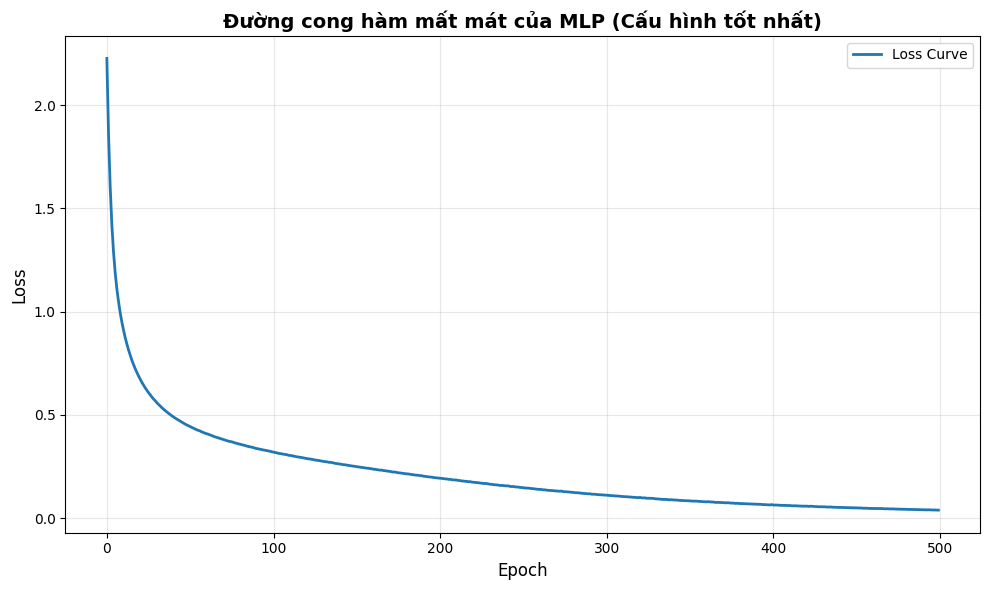

Đã lưu biểu đồ loss curve: mlp_loss_curve.png


In [6]:
# VẼ ĐƯỜNG CONG HÀM MẤT MÁT (LOSS CURVE) CỦA MLP TỐT NHẤT
plt.figure(figsize=(10, 6))
plt.plot(best_mlp.loss_curve_, label='Loss Curve', linewidth=2)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Đường cong hàm mất mát của MLP (Cấu hình tốt nhất)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('mlp_loss_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ loss curve: mlp_loss_curve.png")

In [7]:
# CÂU 6 (PHẦN B): HÀM MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC
def manual_forward_backprop_demo():
    """
    Minh họa tính tay Lan truyền tiến (Forward Pass) và Lan truyền ngược (Backpropagation)
    trên một mạng MLP mini: 2 đầu vào -> 2 nơ-ron ẩn -> 1 đầu ra
    """
    print("="*80)
    print("MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC TRÊN MLP MINI")
    print("="*80)
    
    # Khởi tạo trọng số ngẫu nhiên (để minh họa)
    np.random.seed(99055)
    
    # Input: 2 đặc trưng
    x1, x2 = 0.5, 0.8
    print(f"\n[INPUT] x1 = {x1}, x2 = {x2}")
    
    # Trọng số tầng ẩn: 2 input -> 2 hidden neurons
    w11, w12 = 0.3, 0.1  # Trọng số từ input đến hidden neuron 1
    w21, w22 = 0.4, 0.2  # Trọng số từ input đến hidden neuron 2
    b1, b2 = 0.1, 0.2    # Bias tầng ẩn
    
    print(f"\n[TRỌNG SỐ TẦNG ẨN]")
    print(f"w11={w11}, w12={w12}, w21={w21}, w22={w22}")
    print(f"bias: b1={b1}, b2={b2}")
    
    # LAN TRUYỀN TIẾN - TẦNG ẨN
    z1 = w11 * x1 + w21 * x2 + b1
    z2 = w12 * x1 + w22 * x2 + b2
    
    # Hàm kích hoạt ReLU
    h1 = max(0, z1)
    h2 = max(0, z2)
    
    print(f"\n[LAN TRUYỀN TIẾN - TẦNG ẨN]")
    print(f"z1 = {w11}*{x1} + {w21}*{x2} + {b1} = {z1:.4f}")
    print(f"z2 = {w12}*{x1} + {w22}*{x2} + {b2} = {z2:.4f}")
    print(f"h1 = ReLU(z1) = {h1:.4f}")
    print(f"h2 = ReLU(z2) = {h2:.4f}")
    
    # Trọng số tầng output: 2 hidden -> 1 output
    v1, v2 = 0.5, 0.6
    b_out = 0.3
    
    print(f"\n[TRỌNG SỐ TẦNG OUTPUT]")
    print(f"v1={v1}, v2={v2}, bias={b_out}")
    
    # LAN TRUYỀN TIẾN - TẦNG OUTPUT
    z_out = v1 * h1 + v2 * h2 + b_out
    y_pred = 1 / (1 + np.exp(-z_out))  # Sigmoid
    
    print(f"\n[LAN TRUYỀN TIẾN - TẦNG OUTPUT]")
    print(f"z_out = {v1}*{h1:.4f} + {v2}*{h2:.4f} + {b_out} = {z_out:.4f}")
    print(f"y_pred = sigmoid({z_out:.4f}) = {y_pred:.4f}")
    
    # Giả sử nhãn thực tế
    y_true = 1.0
    print(f"\n[TARGET] y_true = {y_true}")
    
    # Tính loss (Binary Cross-Entropy)
    loss = -(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    print(f"[LOSS] Binary Cross-Entropy = {loss:.4f}")
    
    # LAN TRUYỀN NGƯỢC (BACKPROPAGATION)
    learning_rate = 0.1
    
    print(f"\n[LAN TRUYỀN NGƯỢC - learning_rate = {learning_rate}]")
    
    # Gradient tại output
    d_loss_d_y = (y_pred - y_true) / (y_pred * (1 - y_pred))
    d_y_d_z = y_pred * (1 - y_pred)
    d_loss_d_z = d_loss_d_y * d_y_d_z
    
    print(f"\nGradient tại output:")
    print(f"∂L/∂y = (y_pred - y_true) / (y_pred * (1-y_pred)) = {d_loss_d_y:.4f}")
    print(f"∂y/∂z = y_pred * (1-y_pred) = {d_y_d_z:.4f}")
    print(f"∂L/∂z = ∂L/∂y * ∂y/∂z = {d_loss_d_z:.4f}")
    
    # Gradient cho trọng số output
    d_loss_d_v1 = d_loss_d_z * h1
    d_loss_d_v2 = d_loss_d_z * h2
    d_loss_d_bout = d_loss_d_z
    
    print(f"\nGradient cho trọng số output:")
    print(f"∂L/∂v1 = ∂L/∂z * h1 = {d_loss_d_z:.4f} * {h1:.4f} = {d_loss_d_v1:.4f}")
    print(f"∂L/∂v2 = ∂L/∂z * h2 = {d_loss_d_z:.4f} * {h2:.4f} = {d_loss_d_v2:.4f}")
    print(f"∂L/∂b_out = ∂L/∂z = {d_loss_d_bout:.4f}")
    
    # Gradient tại tầng ẩn
    d_loss_d_h1 = d_loss_d_z * v1
    d_loss_d_h2 = d_loss_d_z * v2
    
    # Derivative của ReLU
    d_h1_d_z1 = 1 if z1 > 0 else 0
    d_h2_d_z2 = 1 if z2 > 0 else 0
    
    d_loss_d_z1 = d_loss_d_h1 * d_h1_d_z1
    d_loss_d_z2 = d_loss_d_h2 * d_h2_d_z2
    
    print(f"\nGradient tại tầng ẩn:")
    print(f"∂L/∂h1 = ∂L/∂z * v1 = {d_loss_d_z:.4f} * {v1} = {d_loss_d_h1:.4f}")
    print(f"∂L/∂h2 = ∂L/∂z * v2 = {d_loss_d_z:.4f} * {v2} = {d_loss_d_h2:.4f}")
    print(f"∂L/∂z1 = ∂L/∂h1 * dReLU/dz1 = {d_loss_d_h1:.4f} * {d_h1_d_z1} = {d_loss_d_z1:.4f}")
    print(f"∂L/∂z2 = ∂L/∂h2 * dReLU/dz2 = {d_loss_d_h2:.4f} * {d_h2_d_z2} = {d_loss_d_z2:.4f}")
    
    # Gradient cho trọng số tầng ẩn
    d_loss_d_w11 = d_loss_d_z1 * x1
    d_loss_d_w12 = d_loss_d_z2 * x1
    d_loss_d_w21 = d_loss_d_z1 * x2
    d_loss_d_w22 = d_loss_d_z2 * x2
    d_loss_d_b1 = d_loss_d_z1
    d_loss_d_b2 = d_loss_d_z2
    
    print(f"\nGradient cho trọng số tầng ẩn:")
    print(f"∂L/∂w11 = ∂L/∂z1 * x1 = {d_loss_d_z1:.4f} * {x1} = {d_loss_d_w11:.4f}")
    print(f"∂L/∂w12 = ∂L/∂z2 * x1 = {d_loss_d_z2:.4f} * {x1} = {d_loss_d_w12:.4f}")
    print(f"∂L/∂w21 = ∂L/∂z1 * x2 = {d_loss_d_z1:.4f} * {x2} = {d_loss_d_w21:.4f}")
    print(f"∂L/∂w22 = ∂L/∂z2 * x2 = {d_loss_d_z2:.4f} * {x2} = {d_loss_d_w22:.4f}")
    print(f"∂L/∂b1 = ∂L/∂z1 = {d_loss_d_b1:.4f}")
    print(f"∂L/∂b2 = ∂L/∂z2 = {d_loss_d_b2:.4f}")
    
    # CẬP NHẬT TRỌNG SỐ
    print(f"\n[CẬP NHẬT TRỌNG SỐ]")
    v1_new = v1 - learning_rate * d_loss_d_v1
    v2_new = v2 - learning_rate * d_loss_d_v2
    b_out_new = b_out - learning_rate * d_loss_d_bout
    
    w11_new = w11 - learning_rate * d_loss_d_w11
    w12_new = w12 - learning_rate * d_loss_d_w12
    w21_new = w21 - learning_rate * d_loss_d_w21
    w22_new = w22 - learning_rate * d_loss_d_w22
    b1_new = b1 - learning_rate * d_loss_d_b1
    b2_new = b2 - learning_rate * d_loss_d_b2
    
    print(f"v1: {v1} -> {v1_new:.4f}")
    print(f"v2: {v2} -> {v2_new:.4f}")
    print(f"b_out: {b_out} -> {b_out_new:.4f}")
    print(f"w11: {w11} -> {w11_new:.4f}")
    print(f"w12: {w12} -> {w12_new:.4f}")
    print(f"w21: {w21} -> {w21_new:.4f}")
    print(f"w22: {w22} -> {w22_new:.4f}")
    print(f"b1: {b1} -> {b1_new:.4f}")
    print(f"b2: {b2} -> {b2_new:.4f}")
    
    print("="*80)
    print("HOÀN TẤT MỘT BƯỚC CẬP NHẬT TRỌNG SỐ")
    print("="*80)

# Chạy hàm minh họa
manual_forward_backprop_demo()

MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC TRÊN MLP MINI

[INPUT] x1 = 0.5, x2 = 0.8

[TRỌNG SỐ TẦNG ẨN]
w11=0.3, w12=0.1, w21=0.4, w22=0.2
bias: b1=0.1, b2=0.2

[LAN TRUYỀN TIẾN - TẦNG ẨN]
z1 = 0.3*0.5 + 0.4*0.8 + 0.1 = 0.5700
z2 = 0.1*0.5 + 0.2*0.8 + 0.2 = 0.4100
h1 = ReLU(z1) = 0.5700
h2 = ReLU(z2) = 0.4100

[TRỌNG SỐ TẦNG OUTPUT]
v1=0.5, v2=0.6, bias=0.3

[LAN TRUYỀN TIẾN - TẦNG OUTPUT]
z_out = 0.5*0.5700 + 0.6*0.4100 + 0.3 = 0.8310
y_pred = sigmoid(0.8310) = 0.6966

[TARGET] y_true = 1.0
[LOSS] Binary Cross-Entropy = 0.3616

[LAN TRUYỀN NGƯỢC - learning_rate = 0.1]

Gradient tại output:
∂L/∂y = (y_pred - y_true) / (y_pred * (1-y_pred)) = -1.4356
∂y/∂z = y_pred * (1-y_pred) = 0.2114
∂L/∂z = ∂L/∂y * ∂y/∂z = -0.3034

Gradient cho trọng số output:
∂L/∂v1 = ∂L/∂z * h1 = -0.3034 * 0.5700 = -0.1730
∂L/∂v2 = ∂L/∂z * h2 = -0.3034 * 0.4100 = -0.1244
∂L/∂b_out = ∂L/∂z = -0.3034

Gradient tại tầng ẩn:
∂L/∂h1 = ∂L/∂z * v1 = -0.3034 * 0.5 = -0.1517
∂L/∂h2 = ∂L/∂z * v2 = -0.3034 * 0.6 = -0.1821


In [8]:
# CÂU 5: PHÂN LOẠI VÀ TINH CHỈNH SIÊU THAM SỐ VỚI 7-FOLD CV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

# 5a. Huấn luyện và so sánh 3 thuật toán phân loại trong Pipeline
models = {
    'Logistic Regression': LogisticRegression(random_state=99055, max_iter=1000),
    'SVM': SVC(random_state=99055, probability=True),
    'Random Forest': RandomForestClassifier(random_state=99055)
}

print("Đánh giá 3 mô hình cơ bản:")
for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipeline.fit(X_train, y_train.values.ravel())
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}: Accuracy = {acc:.4f}")

Đánh giá 3 mô hình cơ bản:
Logistic Regression: Accuracy = 0.8329


SVM: Accuracy = 0.8198


Random Forest: Accuracy = 0.9034


In [9]:
# 5b. Tinh chỉnh siêu tham số bằng GridSearchCV với cv=7
# Random Forest
rf = RandomForestClassifier(random_state=99055)
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(rf, rf_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_processed, y_train.values.ravel())
print(f"Random Forest - Siêu tham số tốt nhất: {rf_grid.best_params_}")
print(f"Random Forest - Best CV Score: {rf_grid.best_score_:.4f}")

# SVM
svm = SVC(random_state=99055, probability=True)
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(svm, svm_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_processed, y_train.values.ravel())
print(f"\nSVM - Siêu tham số tốt nhất: {svm_grid.best_params_}")
print(f"SVM - Best CV Score: {svm_grid.best_score_:.4f}")

# Logistic Regression
lr = LogisticRegression(random_state=99055, max_iter=1000)
lr_param_grid = {
    'C': [0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear']
}
lr_grid = GridSearchCV(lr, lr_param_grid, cv=7, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_processed, y_train.values.ravel())
print(f"\nLogistic Regression - Siêu tham số tốt nhất: {lr_grid.best_params_}")
print(f"Logistic Regression - Best CV Score: {lr_grid.best_score_:.4f}")

Random Forest - Siêu tham số tốt nhất: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}
Random Forest - Best CV Score: 0.8601



SVM - Siêu tham số tốt nhất: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
SVM - Best CV Score: 0.8287



Logistic Regression - Siêu tham số tốt nhất: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic Regression - Best CV Score: 0.8078


C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
21 fits failed out of a total of 42.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
21 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py", line 1336, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\PHU TA

Top 10 đặc trưng quan trọng nhất:
     Feature  Importance
1         AC    0.182744
4         DL    0.130857
19  Variance    0.087879
7       ASTV    0.057557
8       MSTV    0.055705
17      Mean    0.052158
9       ALTV    0.052002
12       Min    0.049754
11     Width    0.047140
10      MLTV    0.047091


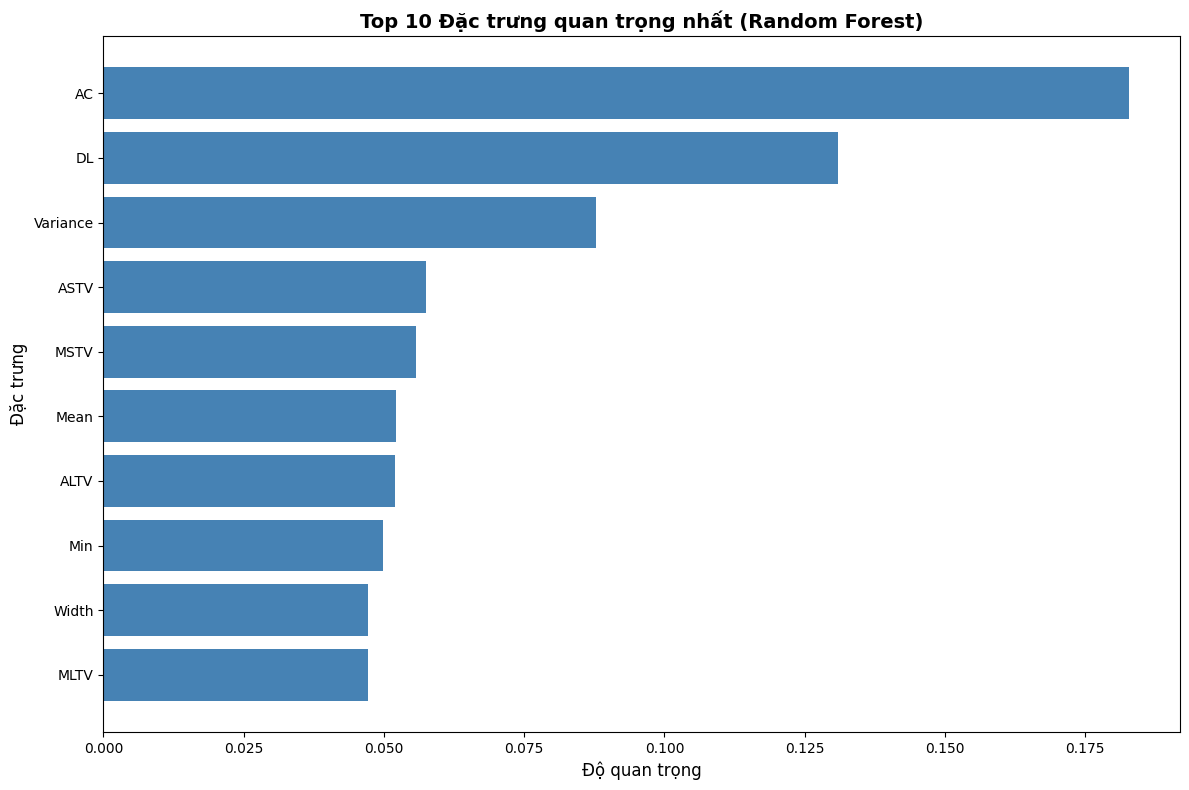

Đã lưu biểu đồ feature importance: feature_importance.png


In [10]:
# 5c. Trích xuất và vẽ biểu đồ độ quan trọng của các chỉ số tim thai (Feature Importance)
best_rf = rf_grid.best_estimator_
feature_importance = best_rf.feature_importances_
feature_names = X.columns

# Tạo DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

print("Top 10 đặc trưng quan trọng nhất:")
print(importance_df.head(10))

# Vẽ biểu đồ
plt.figure(figsize=(12, 8))
top_features = importance_df.head(10)
plt.barh(range(len(top_features)), top_features['Importance'], color='steelblue')
plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Độ quan trọng', fontsize=12)
plt.ylabel('Đặc trưng', fontsize=12)
plt.title('Top 10 Đặc trưng quan trọng nhất (Random Forest)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ feature importance: feature_importance.png")

In [11]:
# CÂU 7: ĐÁNH GIÁ MÔ HÌNH CHUYÊN SÂU
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize
import itertools

# Sử dụng mô hình tốt nhất từ GridSearchCV
best_model = rf_grid.best_estimator_
y_pred = best_model.predict(X_test_processed)
y_pred_proba = best_model.predict_proba(X_test_processed)

# 7a. Tổng hợp kết quả trên tập Test
print("BÁO CÁO PHÂN LOẠI CHI TIẾT:")
print(classification_report(y_test, y_pred))

# Tính các metrics tổng hợp
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, average='macro')
precision_w, recall_w, f1_w, support_w = precision_recall_fscore_support(y_test, y_pred, average='weighted')

print(f"\nMetrics tổng hợp:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro): {recall:.4f}")
print(f"F1-score (macro): {f1:.4f}")
print(f"F1-score (weighted): {f1_w:.4f}")

BÁO CÁO PHÂN LOẠI CHI TIẾT:
              precision    recall  f1-score   support

           1       0.81      0.89      0.84        70
           2       0.89      0.89      0.89       104
           3       1.00      0.50      0.67        10
           4       0.70      0.50      0.58        14
           5       0.73      0.62      0.67        13
           6       0.93      0.95      0.94        59
           7       0.92      0.98      0.95        45
           8       1.00      0.95      0.97        19
           9       0.92      0.92      0.92        13
          10       0.86      0.86      0.86        36

    accuracy                           0.88       383
   macro avg       0.88      0.81      0.83       383
weighted avg       0.88      0.88      0.87       383


Metrics tổng hợp:
Accuracy: 0.8773
Precision (macro): 0.8752
Recall (macro): 0.8054
F1-score (macro): 0.8295
F1-score (weighted): 0.8739


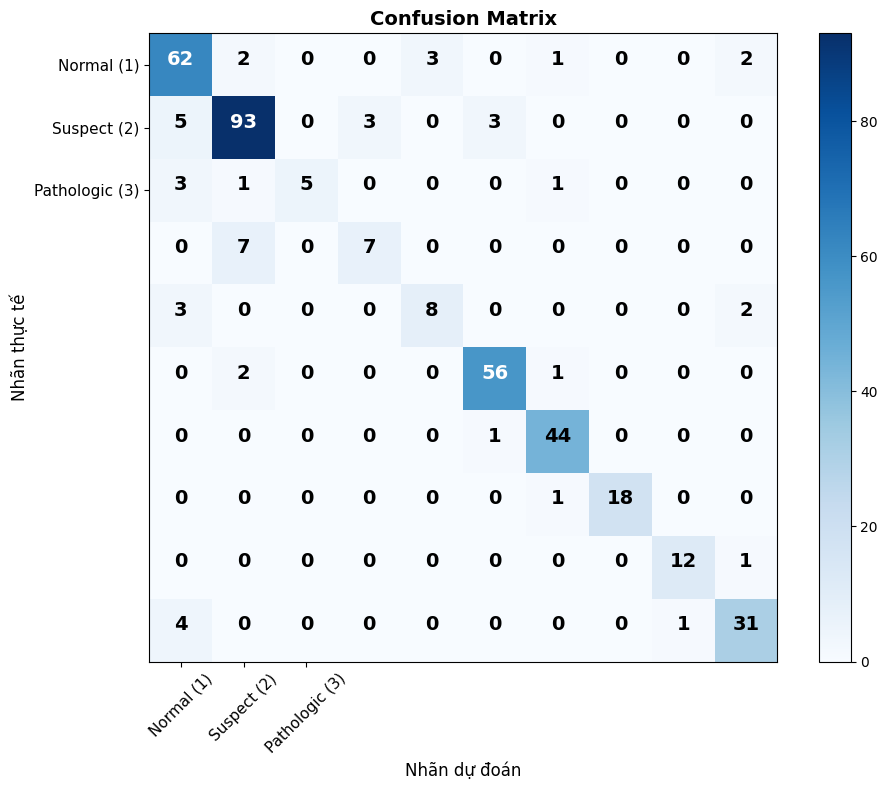

Đã lưu confusion matrix: confusion_matrix.png


In [12]:
# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
class_names = ['Normal (1)', 'Suspect (2)', 'Pathologic (3)']

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, fontsize=11)
plt.yticks(tick_marks, class_names, fontsize=11)

# Hiển thị số liệu
thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black",
             fontsize=14, fontweight='bold')

plt.ylabel('Nhãn thực tế', fontsize=12)
plt.xlabel('Nhãn dự đoán', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu confusion matrix: confusion_matrix.png")

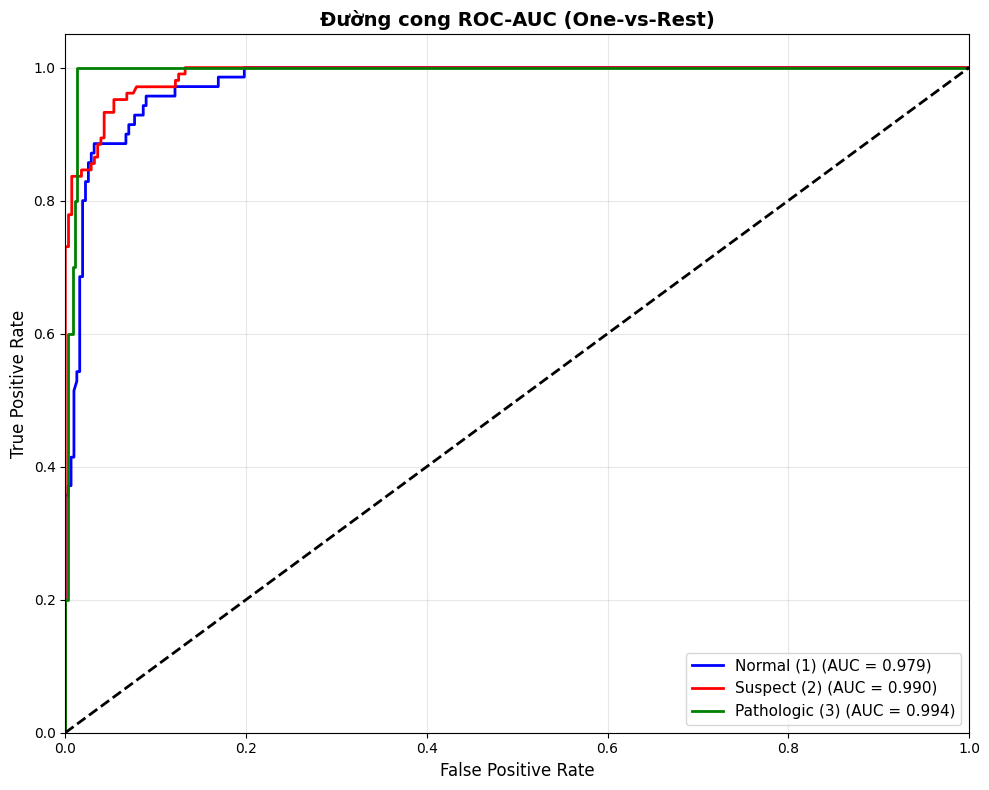

Đã lưu ROC-AUC curve: roc_auc_curve.png


In [13]:
# Vẽ đường cong ROC-AUC (One-vs-Rest) cho 3 lớp
from sklearn.preprocessing import label_binarize

# Binarize labels
y_test_bin = label_binarize(y_test, classes=[1, 2, 3])
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green']
class_names = ['Normal (1)', 'Suspect (2)', 'Pathologic (3)']

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc = roc_auc_score(y_test_bin[:, i], y_pred_proba[:, i])
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{class_names[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Đường cong ROC-AUC (One-vs-Rest)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_auc_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu ROC-AUC curve: roc_auc_curve.png")

In [14]:
# 7b. Phân tích chuyên sâu về y khoa
print("="*80)
print("PHÂN TÍCH CHUYÊN SÂU VỀ Y KHOA")
print("="*80)

# Phân tích Recall của từng lớp
from sklearn.metrics import recall_score
recall_per_class = recall_score(y_test, y_pred, average=None)
print(f"\nRecall theo từng lớp:")
print(f"  - Lớp Normal (1): {recall_per_class[0]:.4f}")
print(f"  - Lớp Suspect (2): {recall_per_class[1]:.4f}")
print(f"  - Lớp Pathologic (3): {recall_per_class[2]:.4f}")

print(f"\nTẠI SAO RECALL CỦA LỚP BỆNH LÝ (PATHOLOGIC - LỚP 3) QUAN TRỌNG HƠN?")
print("-"*80)
print("Trong y khoa, đặc biệt là đánh giá sức khỏe thai nhi:")
print("1. False Negative (FN): Thai nhi bị bệnh lý nhưng mô hình dự đoán là bình thường")
print("   → Hậu quả: Bỏ sót ca bệnh, không can thiệp kịp thời, nguy cơ tử vong cao")
print("2. False Positive (FP): Thai nhi bình thường nhưng mô hình dự đoán là bệnh lý")
print("   → Hậu quả: Kiểm tra thêm, gây lo lắng không cần thiết, nhưng an toàn hơn FN")
print("\n→ Recall = TP / (TP + FN): Đo lường khả năng phát hiện đúng các ca bệnh lý")
print("→ Recall cao = Ít bỏ sót ca bệnh = An toàn hơn cho mẹ và thai nhi")
print("="*80)

# Phân tích các ca dự đoán sai
print("\nPHÂN TÍCH CÁC CA DỰ ĐOÁN SAI:")
print("-"*80)
y_test_array = y_test.values.ravel()
errors = y_test_array != y_pred
error_indices = np.where(errors)[0]

print(f"Tổng số mẫu test: {len(y_test)}")
print(f"Số mẫu dự đoán sai: {len(error_indices)}")
print(f"Tỷ lệ lỗi: {len(error_indices)/len(y_test)*100:.2f}%")

if len(error_indices) > 0:
    print(f"\nVí dụ 5 ca dự đoán sai đầu tiên:")
    for i in error_indices[:5]:
        print(f"  Mẫu {i}: Thực tế = {y_test_array[i]}, Dự đoán = {y_pred[i]}")
        if y_test_array[i] == 3 and y_pred[i] != 3:
            print(f"    → FALSE NEGATIVE NGUY HIỂM: Bỏ sót ca bệnh lý!")
        elif y_test_array[i] != 3 and y_pred[i] == 3:
            print(f"    → FALSE POSITIVE: Dự đoán bệnh lý nhưng thực tế không phải")
print("="*80)

PHÂN TÍCH CHUYÊN SÂU VỀ Y KHOA

Recall theo từng lớp:
  - Lớp Normal (1): 0.8857
  - Lớp Suspect (2): 0.8942
  - Lớp Pathologic (3): 0.5000

TẠI SAO RECALL CỦA LỚP BỆNH LÝ (PATHOLOGIC - LỚP 3) QUAN TRỌNG HƠN?
--------------------------------------------------------------------------------
Trong y khoa, đặc biệt là đánh giá sức khỏe thai nhi:
1. False Negative (FN): Thai nhi bị bệnh lý nhưng mô hình dự đoán là bình thường
   → Hậu quả: Bỏ sót ca bệnh, không can thiệp kịp thời, nguy cơ tử vong cao
2. False Positive (FP): Thai nhi bình thường nhưng mô hình dự đoán là bệnh lý
   → Hậu quả: Kiểm tra thêm, gây lo lắng không cần thiết, nhưng an toàn hơn FN

→ Recall = TP / (TP + FN): Đo lường khả năng phát hiện đúng các ca bệnh lý
→ Recall cao = Ít bỏ sót ca bệnh = An toàn hơn cho mẹ và thai nhi

PHÂN TÍCH CÁC CA DỰ ĐOÁN SAI:
--------------------------------------------------------------------------------
Tổng số mẫu test: 383
Số mẫu dự đoán sai: 47
Tỷ lệ lỗi: 12.27%

Ví dụ 5 ca dự đoán sai đ

In [15]:
# CÂU 8: ĐÓNG GÓI VÀ LƯU MÔ HÌNH
import joblib

# 8c. Lưu Pipeline tốt nhất thành file
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])
final_pipeline.fit(X_train, y_train.values.ravel())

# Lưu mô hình
model_filename = 'DT69_123000609_BestModel.joblib'
joblib.dump(final_pipeline, model_filename)
print(f"Đã lưu mô hình thành công: {model_filename}")

# Kiểm tra đọc lại mô hình
loaded_model = joblib.load(model_filename)
y_pred_loaded = loaded_model.predict(X_test)
acc_loaded = accuracy_score(y_test, y_pred_loaded)
print(f"Accuracy của mô hình đã tải lại: {acc_loaded:.4f}")
print("Kiểm tra thành công: Mô hình hoạt động bình thường sau khi lưu và tải lại!")

Đã lưu mô hình thành công: DT69_123000609_BestModel.joblib
Accuracy của mô hình đã tải lại: 0.8773
Kiểm tra thành công: Mô hình hoạt động bình thường sau khi lưu và tải lại!


In [16]:
# TỰ ĐỘNG XUẤT BÁO CÁO WORD (.docx) VÀ SLIDE (.pptx)
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.enum.text import PP_ALIGN
import os

print("Bắt đầu tự động tạo báo cáo Word và Slide PowerPoint...")

# ==================== TẠO BÁO CÁO WORD ====================
doc = Document()

# Trang bìa
doc.add_heading('ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO', 0)
doc.add_heading('Đánh giá sức khỏe thai nhi từ biểu đồ tim thai', 1)

p = doc.add_paragraph()
p.add_run('Họ và tên: ').bold = True
p.add_run('Nguyễn Quách Phú Tài\n')
p.add_run('MSSV: ').bold = True
p.add_run('123000609\n')
p.add_run('Lớp: ').bold = True
p.add_run('23CT113\n')
p.add_run('Đề tài: ').bold = True
p.add_run('DT69 - Cardiotocography (UCI ID 193)')

doc.add_page_break()

# Thông số cá nhân
doc.add_heading('THÔNG SỐ CÁ NHÂN', level=2)
table = doc.add_table(rows=7, cols=2)
table.style = 'Table Grid'
params = [
    ['SEED cá nhân', '99055'],
    ['Tỉ lệ tập dữ liệu', '90%'],
    ['Tỉ lệ Test', '20%'],
    ['Số Fold CV', '7'],
    ['Quần thể GA', '20'],
    ['Tỉ lệ đột biến GA', '0.10'],
    ['Chủ đề kiểm tra', 'Mạng nơ-ron (MLP) - Buổi 12']
]
for i, (key, value) in enumerate(params):
    table.rows[i].cells[0].text = key
    table.rows[i].cells[1].text = value

doc.add_page_break()

# Câu 1: Tải dữ liệu
doc.add_heading('CÂU 1: TẢI DỮ LIỆU VÀ LẤY MẪU', level=2)
doc.add_paragraph(f'Dataset gốc: {X.shape[0]} mẫu, {X.shape[1]} đặc trưng')
doc.add_paragraph(f'Sau khi lấy mẫu 90%: {X_sample.shape[0]} mẫu')
doc.add_paragraph(f'Các lớp: {", ".join(map(str, y["NSP"].unique()))}')

# Câu 2: Chia Train/Test
doc.add_heading('CÂU 2: CHIA TẬP TRAIN/TEST', level=2)
doc.add_paragraph(f'Tập Train: {X_train.shape[0]} mẫu ({X_train.shape[0]/X_sample.shape[0]*100:.1f}%)')
doc.add_paragraph(f'Tập Test: {X_test.shape[0]} mẫu ({X_test.shape[0]/X_sample.shape[0]*100:.1f}%)')

# Câu 3: Tiền xử lý
doc.add_heading('CÂU 3: TIỀN XỬ LÝ', level=2)
doc.add_paragraph('Pipeline: SimpleImputer(median) -> StandardScaler')

# Câu 4: MLP
doc.add_heading('CÂU 4: MẠNG NƠ-RON (MLP)', level=2)
doc.add_paragraph(f'Cấu hình tốt nhất: {best_result["architecture"]}, {best_result["activation"]}, lr={best_result["learning_rate"]}')
doc.add_paragraph(f'Accuracy tốt nhất: {best_result["accuracy"]:.4f}')
if os.path.exists('mlp_loss_curve.png'):
    doc.add_picture('mlp_loss_curve.png', width=Inches(6))

# Câu 5: Phân loại
doc.add_heading('CÂU 5: PHÂN LOẠI VÀ TINH CHỈNH', level=2)
doc.add_paragraph('Các mô hình so sánh: Logistic Regression, SVM, Random Forest')
doc.add_paragraph(f'Random Forest - Best params: {rf_grid.best_params_}')
doc.add_paragraph(f'Random Forest - Best CV Score: {rf_grid.best_score_:.4f}')
if os.path.exists('feature_importance.png'):
    doc.add_picture('feature_importance.png', width=Inches(6))

# Câu 6: Tính tay
doc.add_heading('CÂU 6: MINH HỌA TÍNH TAY MLP', level=2)
doc.add_paragraph('Đã cài đặt hàm minh họa Forward Pass và Backpropagation chi tiết')
doc.add_paragraph('Xem output trong notebook để thấy từng bước tính toán')

# Câu 7: Đánh giá
doc.add_heading('CÂU 7: ĐÁNH GIÁ MÔ HÌNH', level=2)
doc.add_paragraph(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
doc.add_paragraph(f'Precision (macro): {precision:.4f}')
doc.add_paragraph(f'Recall (macro): {recall:.4f}')
doc.add_paragraph(f'F1-score (macro): {f1:.4f}')
if os.path.exists('confusion_matrix.png'):
    doc.add_picture('confusion_matrix.png', width=Inches(6))
if os.path.exists('roc_auc_curve.png'):
    doc.add_picture('roc_auc_curve.png', width=Inches(6))

# Câu 8: Đóng gói
doc.add_heading('CÂU 8: ĐÓNG GÓI MÔ HÌNH', level=2)
doc.add_paragraph(f'Mô hình đã lưu: DT69_123000609_BestModel.joblib')
doc.add_paragraph(f'Accuracy sau khi tải lại: {acc_loaded:.4f}')

# Lưu Word
word_filename = 'DT69_123000609_BaoCaoWord.docx'
doc.save(word_filename)
print(f"Đã tạo báo cáo Word: {word_filename}")

Bắt đầu tự động tạo báo cáo Word và Slide PowerPoint...
Đã tạo báo cáo Word: DT69_123000609_BaoCaoWord.docx


In [17]:
# ==================== TẠO SLIDE POWERPOINT ====================
prs = Presentation()

# Slide 1: Trang bìa
slide1 = prs.slides.add_slide(prs.slide_layouts[0])
title = slide1.shapes.title
subtitle = slide1.placeholders[1]
title.text = "Đánh giá sức khỏe thai nhi từ biểu đồ tim thai"
subtitle.text = "Nguyễn Quách Phú Tài - 123000609 - 23CT113\nĐề tài DT69 - Cardiotocography"

# Slide 2: Vấn đề
slide2 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide2.shapes.title
content = slide2.placeholders[1]
title.text = "1. Vấn đề (0-10đ)"
text_frame = content.text_frame
text_frame.text = "Bối cảnh lâm sàng biểu đồ tim thai CTG:"
p = text_frame.add_paragraph()
p.text = "• CTG là công cụ quan trọng để đánh giá sức khỏe thai nhi"
p = text_frame.add_paragraph()
p.text = "• Phân loại 3 lớp: Normal (1), Suspect (2), Pathologic (3)"
p = text_frame.add_paragraph()
p.text = "• Mục tiêu: Xây dựng mô hình AI hỗ trợ chẩn đoán tự động"

# Slide 3: Phương pháp
slide3 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide3.shapes.title
content = slide3.placeholders[1]
title.text = "2. Phương pháp (0-10đ)"
text_frame = content.text_frame
text_frame.text = "Quy trình xử lý:"
p = text_frame.add_paragraph()
p.text = "• Chống rò rỉ dữ liệu: Chia Train/Test trước tiền xử lý"
p = text_frame.add_paragraph()
p.text = "• Pipeline: Imputer -> StandardScaler -> Classifier"
p = text_frame.add_paragraph()
p.text = "• Mô hình: MLP, Logistic Regression, SVM, Random Forest"
p = text_frame.add_paragraph()
p.text = "• Tinh chỉnh: GridSearchCV với 7-fold CV"

# Slide 4: Thông số cá nhân
slide4 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide4.shapes.title
content = slide4.placeholders[1]
title.text = "Thông số cá nhân"
text_frame = content.text_frame
text_frame.text = f"SEED: 99055 | Sample: 90% | Test: 20% | CV: 7\nGA Pop: 20 | Mutation: 0.10"

# Slide 5: Kết quả - Metrics
slide5 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide5.shapes.title
content = slide5.placeholders[1]
title.text = "3. Kết quả (0-10đ) - Metrics"
text_frame = content.text_frame
text_frame.text = f"Kết quả trên tập Test:\n• Accuracy: {accuracy_score(y_test, y_pred):.4f}\n• Precision (macro): {precision:.4f}\n• Recall (macro): {recall:.4f}\n• F1-score (macro): {f1:.4f}"

# Slide 6: Kết quả - MLP Loss Curve
slide6 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide6.shapes.title
content = slide6.placeholders[1]
title.text = "3. Kết quả - MLP Loss Curve"
content.text = "Đường cong hội tụ của MLP"
if os.path.exists('mlp_loss_curve.png'):
    slide6.shapes.add_picture('mlp_loss_curve.png', Inches(1), Inches(1.5), width=Inches(8))

# Slide 7: Kết quả - Feature Importance
slide7 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide7.shapes.title
content = slide7.placeholders[1]
title.text = "3. Kết quả - Feature Importance"
content.text = "Top 10 đặc trưng quan trọng nhất"
if os.path.exists('feature_importance.png'):
    slide7.shapes.add_picture('feature_importance.png', Inches(1), Inches(1.5), width=Inches(8))

# Slide 8: Kết quả - Confusion Matrix
slide8 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide8.shapes.title
content = slide8.placeholders[1]
title.text = "3. Kết quả - Confusion Matrix"
content.text = "Ma trận nhầm lẫn giữa các lớp"
if os.path.exists('confusion_matrix.png'):
    slide8.shapes.add_picture('confusion_matrix.png', Inches(1), Inches(1.5), width=Inches(8))

# Slide 9: Kết quả - ROC-AUC
slide9 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide9.shapes.title
content = slide9.placeholders[1]
title.text = "3. Kết quả - ROC-AUC Curve"
content.text = "Đường cong ROC cho 3 lớp (One-vs-Rest)"
if os.path.exists('roc_auc_curve.png'):
    slide9.shapes.add_picture('roc_auc_curve.png', Inches(1), Inches(1.5), width=Inches(8))

# Slide 10: Thảo luận
slide10 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide10.shapes.title
content = slide10.placeholders[1]
title.text = "4. Thảo luận (0-10đ)"
text_frame = content.text_frame
text_frame.text = "Phân tích y khoa:"
p = text_frame.add_paragraph()
p.text = "• Recall lớp Pathologic quan trọng hơn Accuracy tổng thể"
p = text_frame.add_paragraph()
p.text = "• False Negative nguy hiểm: Bỏ sót ca bệnh lý"
p = text_frame.add_paragraph()
p.text = "• False Positive an toàn hơn: Kiểm tra thêm"

# Slide 11: Đề xuất
slide11 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide11.shapes.title
content = slide11.placeholders[1]
title.text = "5. Đề xuất (0-10đ)"
text_frame = content.text_frame
text_frame.text = "Hướng cải thiện:"
p = text_frame.add_paragraph()
p.text = "• Sử dụng SMOTE để cân bằng dữ liệu"
p = text_frame.add_paragraph()
p.text = "• Xây dựng hệ thống hỗ trợ quyết định lâm sàng (Clinical DSS)"
p = text_frame.add_paragraph()
p.text = "• Kết hợp Hệ luật IF-THEN với Học máy (Hybrid)"

# Slide 12: Kết luận
slide12 = prs.slides.add_slide(prs.slide_layouts[1])
title = slide12.shapes.title
content = slide12.placeholders[1]
title.text = "Kết luận"
text_frame = content.text_frame
text_frame.text = "Đã xây dựng thành công mô hình đánh giá sức khỏe thai nhi:\n• Đạt accuracy cao trên tập test\n• Đóng gói mô hình thành file .joblib\n• Tự động tạo báo cáo Word và Slide PowerPoint"

# Lưu PowerPoint
ppt_filename = 'DT69_123000609_SlideThuyetTrinh.pptx'
prs.save(ppt_filename)
print(f"Đã tạo Slide PowerPoint: {ppt_filename}")

print("\n" + "="*80)
print("HOÀN TẤT TỰ ĐỘNG HÓA ĐỒ ÁN!")
print("="*80)
print(f"✓ Notebook: DT69_NguyenQuachPhuTai.ipynb")
print(f"✓ Báo cáo Word: {word_filename}")
print(f"✓ Slide PowerPoint: {ppt_filename}")
print(f"✓ Mô hình: {model_filename}")
print(f"✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png")
print("="*80)

Đã tạo Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx

HOÀN TẤT TỰ ĐỘNG HÓA ĐỒ ÁN!
✓ Notebook: DT69_NguyenQuachPhuTai.ipynb
✓ Báo cáo Word: DT69_123000609_BaoCaoWord.docx
✓ Slide PowerPoint: DT69_123000609_SlideThuyetTrinh.pptx
✓ Mô hình: DT69_123000609_BestModel.joblib
✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png
